# Proyecto final: Airbnb Bogotá
## Pregunta 2: ¿qué nivel de ocupación anual tendrá un alojamiento según sus características?

**Datos:** Inside Airbnb, Bogotá, septiembre 2026 (la misma tabla `listings` de la pregunta 1).
**Variable a predecir (y):** `estimated_occupancy_l365d`, las noches ocupadas estimadas en el último año.
**Tipo de problema:** regresión, porque es un número (de 0 a 255 noches).
**Ojo:** es una estimación que calcula Inside Airbnb a partir de los comentarios, no son reservas reales. Por eso no uso como variables de entrada nada que salga de los comentarios ni de la disponibilidad (serían una fuga).

In [1]:
import warnings                                   # módulo para controlar los avisos (warnings) de Python
warnings.filterwarnings("ignore")                 # oculta los avisos para que el notebook se vea limpio

from pathlib import Path                          # Path sirve para manejar rutas de carpetas y archivos
import numpy as np                                # numpy: operaciones matemáticas y arreglos numéricos
import pandas as pd                               # pandas: manejo de tablas (DataFrames)
import matplotlib.pyplot as plt                   # matplotlib: para hacer gráficos
import seaborn as sns                             # seaborn: gráficos estadísticos más bonitos, se apoya en matplotlib

from sklearn.base import BaseEstimator, TransformerMixin   # clases base para crear mis propios transformadores
from sklearn.model_selection import train_test_split       # divide los datos en entrenamiento y prueba
from sklearn.model_selection import KFold                  # define cómo partir los datos para la validación cruzada
from sklearn.model_selection import cross_validate         # corre la validación cruzada y devuelve las métricas
from sklearn.compose import ColumnTransformer              # aplica un tratamiento distinto a cada grupo de columnas
from sklearn.compose import TransformedTargetRegressor     # entrena el modelo sobre un objetivo transformado (log) y devuelve la predicción en la escala original
from sklearn.pipeline import Pipeline                      # encadena preparación de datos + modelo en un solo objeto
from sklearn.impute import SimpleImputer                   # rellena valores vacíos (nulos)
from sklearn.preprocessing import OneHotEncoder            # convierte categorías (texto) en columnas de 0 y 1
from sklearn.preprocessing import StandardScaler           # pone las variables numéricas en la misma escala
from sklearn.metrics import mean_absolute_error            # MAE: error promedio absoluto
from sklearn.metrics import mean_squared_error             # MSE: error cuadrático (de aquí sale el RMSE)
from sklearn.metrics import r2_score                       # R²: qué proporción de la variación explica el modelo

from sklearn.linear_model import LinearRegression, Ridge   # regresión lineal y su versión con penalización (Ridge)
from sklearn.neighbors import KNeighborsRegressor          # KNN: predice según los vecinos más parecidos
from sklearn.tree import DecisionTreeRegressor             # árbol de decisión
from sklearn.ensemble import RandomForestRegressor         # bosque aleatorio: muchos árboles que votan
from sklearn.ensemble import GradientBoostingRegressor     # boosting: árboles que corrigen los errores del anterior
from sklearn.svm import SVR                                # máquina de soporte vectorial para regresión
from sklearn.neural_network import MLPRegressor            # red neuronal sencilla (perceptrón multicapa)
from xgboost import XGBRegressor                           # XGBoost: boosting optimizado, muy usado en competencias

DATOS = Path("../datos")                          # ruta a la carpeta de datos (sube un nivel desde notebooks/ y entra a datos/)
pd.set_option("display.max_columns", 100)         # pandas mostrará hasta 100 columnas sin recortarlas con "..."
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")   # muestra los decimales con separador de miles y 2 decimales
sns.set_theme(style="whitegrid")                  # estilo de los gráficos: fondo claro con cuadrícula

print("Datos encontrados:", sorted(p.name for p in DATOS.glob("*.csv.gz")))   # lista los archivos .csv.gz de la carpeta datos, ordenados

Datos encontrados: ['calendar.csv.gz', 'listings.csv.gz', 'reviews.csv.gz']


## Paso 1: ¿Necesitamos ML?
Cargo la tabla `listings` (una fila por alojamiento publicado) y miro la variable que quiero predecir: las noches ocupadas estimadas en el último año.

In [2]:
listings = pd.read_csv(                          # lee el archivo CSV comprimido y lo guarda como tabla (DataFrame)
    DATOS / "listings.csv.gz",                   # ruta del archivo: la carpeta datos + el nombre del archivo
    dtype={"price": str},                        # fuerza la columna price a texto (no la voy a usar como variable, pero así se lee igual que en la pregunta 1)
    low_memory=False,                            # lee el archivo completo de una vez para que pandas no adivine mal los tipos de columna
)                                                # cierra la lectura

print("Filas y columnas:", listings.shape)       # muestra cuántas filas (alojamientos) y columnas (variables) tiene la tabla

Filas y columnas: (19505, 90)


In [3]:
y = listings["estimated_occupancy_l365d"]                                  # atajo: la columna que quiero predecir
print("Vacíos:", y.isna().sum())                                           # cuántos alojamientos no tienen este dato
print()                                                                    # línea en blanco para separar
print(y.describe(percentiles=[0.25, 0.5, 0.75, 0.95]))                     # resumen estadístico: promedio, mediana, máximo...
print()                                                                    # línea en blanco para separar
print(f"Alojamientos con 0 noches ocupadas: {(y == 0).mean() * 100:.1f}%")  # qué porcentaje no tuvo ninguna noche ocupada
print(f"Alojamientos en el tope de 255 noches: {(y >= 255).mean() * 100:.1f}%")   # qué porcentaje llegó al máximo posible

Vacíos: 0

count   19,505.00
mean        57.07
std         76.45
min          0.00
25%          0.00
50%         18.00
75%         90.00
95%        255.00
max        255.00
Name: estimated_occupancy_l365d, dtype: float64

Alojamientos con 0 noches ocupadas: 35.0%
Alojamientos en el tope de 255 noches: 5.6%


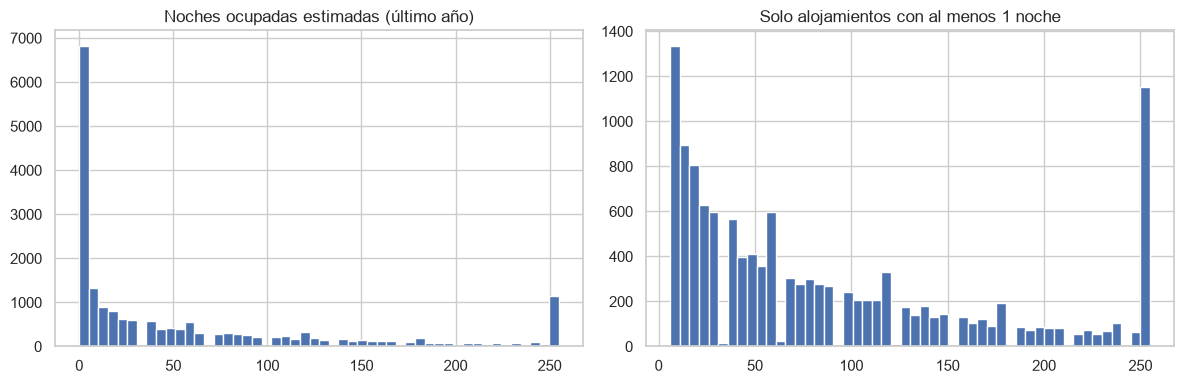

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))                            # crea una figura con dos gráficos lado a lado
ejes[0].hist(y.dropna(), bins=50)                                          # histograma de las noches ocupadas, en 50 barras
ejes[0].set_title("Noches ocupadas estimadas (último año)")                # título del primer gráfico
ejes[1].hist(y[y > 0], bins=50)                                            # histograma solo de los que sí tuvieron ocupación (sin los ceros)
ejes[1].set_title("Solo alojamientos con al menos 1 noche")                # título del segundo gráfico
plt.tight_layout()                                                         # acomoda los gráficos para que no se pisen
plt.show()                                                                 # muestra la figura